In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv("../data/raw/Weather_Factors_And_Yield_Dataset.csv")

df.head()

,YEAR,Station,LATITUDE,LONGITUDE,ALT,Avg_Max_Temp,Avg_Min_Temp,Avg_Rainfall,Avg_Relative_Humidity,Avg_Windspeed,Avg_Cloud_Coverage,Avg_Bright_Sunshine,Aman_Yield,Aus_Yield,Boro_Yield,Avg_YearlyTemp
0,1970,Barisal,0.882582,0.980043,0.063492,0.896552,0.935013,0.436900,0.918843,0.211810,0.805648,0.844641,0.000000,0.000000,0.000000,0.937328
1,1970,Bogra,0.967341,0.969197,0.317460,0.986437,0.916758,0.324823,0.846082,0.157895,0.684385,0.889872,0.230039,0.103879,0.017578,0.986798
2,1970,Chittagong (IAP-Patenga),0.868585,0.995553,0.095238,0.893793,0.942680,0.512041,0.901119,0.378691,0.857143,0.822026,0.261297,0.132488,0.126155,0.938633
3,1970,Comilla,0.912908,0.989046,0.158730,0.921379,0.959109,0.313598,0.953358,0.165597,0.450166,0.776854,0.416261,0.244367,0.125923,0.962571
4,1970,Dhaka,0.924572,0.980369,0.142857,0.917471,0.940489,0.361217,0.853545,0.225931,0.747508,0.925270,0.256093,0.201818,0.124923,0.952706


In [3]:
df.shape

(660, 16)

In [4]:
df.columns

Index(['YEAR', 'Station', 'LATITUDE', 'LONGITUDE', 'ALT', 'Avg_Max_Temp',
       'Avg_Min_Temp', 'Avg_Rainfall', 'Avg_Relative_Humidity',
       'Avg_Windspeed', 'Avg_Cloud_Coverage', 'Avg_Bright_Sunshine',
       'Aman_Yield', 'Aus_Yield', 'Boro_Yield', 'Avg_YearlyTemp'],
      dtype='str')

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   YEAR                   660 non-null    int64  
 1   Station                660 non-null    str    
 2   LATITUDE               660 non-null    float64
 3   LONGITUDE              660 non-null    float64
 4   ALT                    660 non-null    float64
 5   Avg_Max_Temp           660 non-null    float64
 6   Avg_Min_Temp           660 non-null    float64
 7   Avg_Rainfall           660 non-null    float64
 8   Avg_Relative_Humidity  660 non-null    float64
 9   Avg_Windspeed          660 non-null    float64
 10  Avg_Cloud_Coverage     660 non-null    float64
 11  Avg_Bright_Sunshine    660 non-null    float64
 12  Aman_Yield             660 non-null    float64
 13  Aus_Yield              660 non-null    float64
 14  Boro_Yield             660 non-null    float64
 15  Avg_YearlyTemp   

In [6]:
df.isnull().sum()

YEAR                     0
Station                  0
LATITUDE                 0
LONGITUDE                0
ALT                      0
Avg_Max_Temp             0
Avg_Min_Temp             0
Avg_Rainfall             0
Avg_Relative_Humidity    0
Avg_Windspeed            0
Avg_Cloud_Coverage       0
Avg_Bright_Sunshine      0
Aman_Yield               0
Aus_Yield                0
Boro_Yield               0
Avg_YearlyTemp           0
dtype: int64

In [7]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [8]:
df.describe()

,YEAR,LATITUDE,LONGITUDE,ALT,Avg_Max_Temp,Avg_Min_Temp,Avg_Rainfall,Avg_Relative_Humidity,Avg_Windspeed,Avg_Cloud_Coverage,Avg_Bright_Sunshine,Aman_Yield,Aus_Yield,Boro_Yield,Avg_YearlyTemp
count,660.000000,660.000000,660.000000,660.000000,660.000000,660.000000,660.000000,660.000000,660.000000,660.000000,660.000000,660.000000,660.000000,660.000000,660.000000
mean,1991.500000,0.925661,0.978373,0.296296,0.924406,0.916137,0.397646,0.880620,0.221706,0.700654,0.757359,0.340975,0.123054,0.231807,0.947406
std,12.708056,0.043560,0.012136,0.260739,0.067063,0.070372,0.139766,0.069958,0.126392,0.097471,0.084663,0.186326,0.107109,0.226647,0.067732
min,1970.000000,0.868585,0.960521,0.047619,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1980.750000,0.882582,0.968113,0.095238,0.913793,0.899598,0.312013,0.860774,0.143453,0.652824,0.722714,0.223591,0.036296,0.042317,0.938198
50%,1991.500000,0.917963,0.979826,0.158730,0.928506,0.918949,0.372805,0.886660,0.189987,0.709302,0.761754,0.337674,0.113001,0.166788,0.952488
75%,2002.250000,0.967341,0.989046,0.539683,0.945345,0.941402,0.455957,0.909515,0.264442,0.757475,0.797443,0.446038,0.178052,0.373805,0.968229
max,2013.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [9]:
print("Number of stations:", df["Station"].nunique())
print("\nStations:")
print(df["Station"].unique())

Number of stations: 15

Stations:
<ArrowStringArray>
[                 'Barisal',                    'Bogra',
 'Chittagong (IAP-Patenga)',                  'Comilla',
                    'Dhaka',                 'Dinajpur',
                 'Faridpur',                  'Jessore',
                   'Khulna',               'Mymensingh',
                 'Rajshahi',                  'Rangpur',
                   'Sylhet',               'Patuakhali',
                'Rangamati']
Length: 15, dtype: str


In [10]:
df.nunique()

YEAR                      44
Station                   15
LATITUDE                  14
LONGITUDE                 15
ALT                       12
Avg_Max_Temp             324
Avg_Min_Temp             295
Avg_Rainfall             561
Avg_Relative_Humidity    164
Avg_Windspeed            266
Avg_Cloud_Coverage       210
Avg_Bright_Sunshine      251
Aman_Yield               637
Aus_Yield                614
Boro_Yield               601
Avg_YearlyTemp           384
dtype: int64

In [11]:
df.corr(numeric_only=True)["Aman_Yield"].sort_values(ascending=False)

Aman_Yield               1.000000
Boro_Yield               0.456642
LATITUDE                 0.418884
Aus_Yield                0.290998
Avg_Relative_Humidity    0.171673
Avg_Rainfall             0.099380
YEAR                     0.080240
Avg_Cloud_Coverage       0.068151
Avg_Max_Temp             0.055498
Avg_Bright_Sunshine      0.045467
Avg_YearlyTemp           0.003443
ALT                     -0.066709
Avg_Min_Temp            -0.075656
Avg_Windspeed           -0.093075
LONGITUDE               -0.286768
Name: Aman_Yield, dtype: float64

In [12]:
target = "Aman_Yield"

features = [
    "YEAR",
    "Station",
    "LATITUDE",
    "LONGITUDE",
    "ALT",
    "Avg_Max_Temp",
    "Avg_Min_Temp",
    "Avg_Rainfall",
    "Avg_Relative_Humidity",
    "Avg_Windspeed",
    "Avg_Cloud_Coverage",
    "Avg_Bright_Sunshine"
]

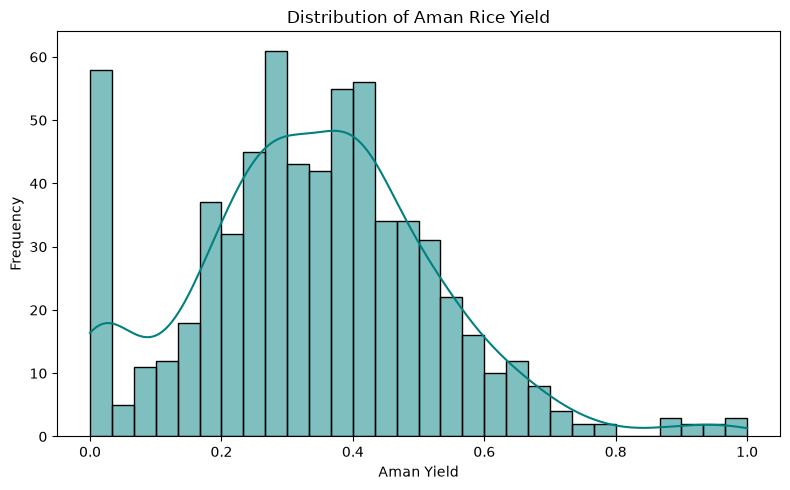

In [13]:
plt.figure(figsize=(8, 5))

sns.histplot(df["Aman_Yield"], bins=30, kde=True, color="teal")

plt.title("Distribution of Aman Rice Yield")
plt.xlabel("Aman Yield")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

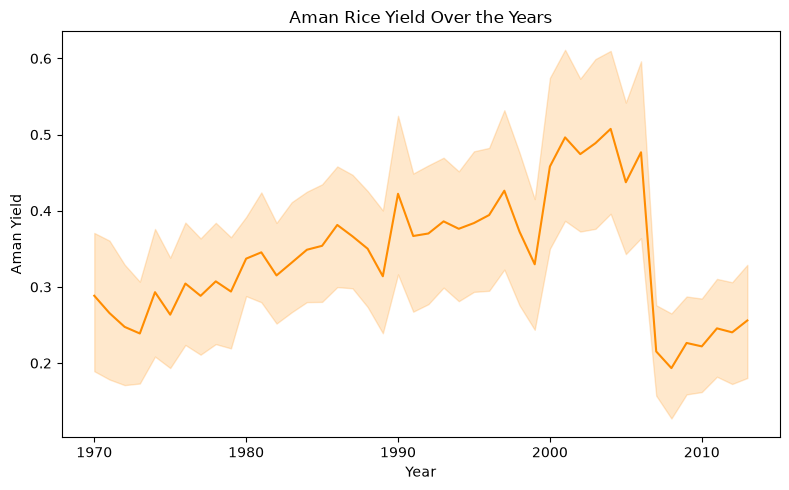

In [14]:
plt.figure(figsize=(8,5))

sns.lineplot(data=df, x="YEAR", y="Aman_Yield", color="darkorange")

plt.title("Aman Rice Yield Over the Years")
plt.xlabel("Year")
plt.ylabel("Aman Yield")
plt.tight_layout()
plt.show()

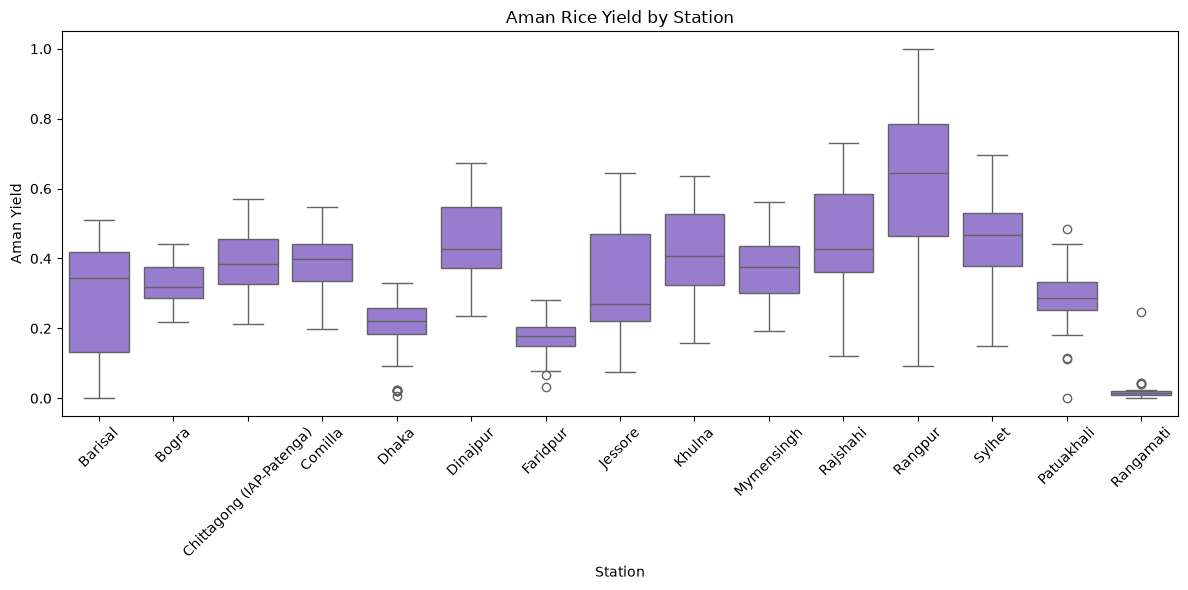

In [15]:
plt.figure(figsize=(12, 6))

sns.boxplot(data=df, x="Station", y="Aman_Yield", color="mediumpurple")

plt.title("Aman Rice Yield by Station")
plt.xlabel("Station")
plt.ylabel("Aman Yield")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

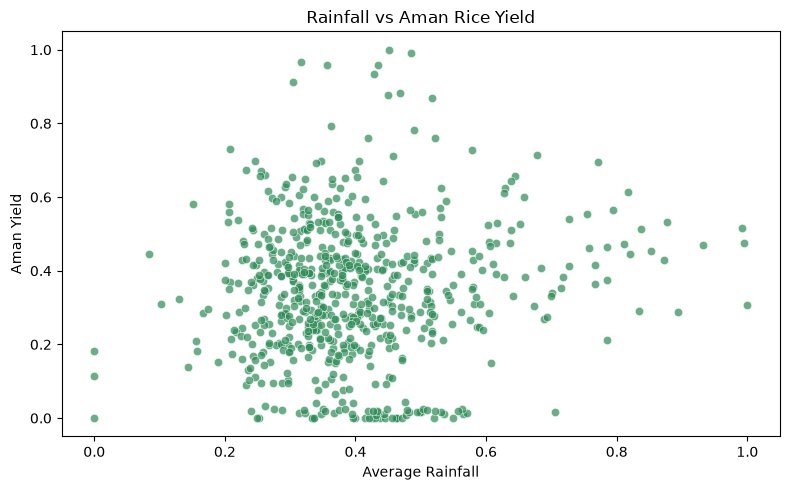

In [16]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Avg_Rainfall",
    y="Aman_Yield",
    color="seagreen",
    alpha=0.7
)

plt.title("Rainfall vs Aman Rice Yield")
plt.xlabel("Average Rainfall")
plt.ylabel("Aman Yield")
plt.tight_layout()
plt.show()

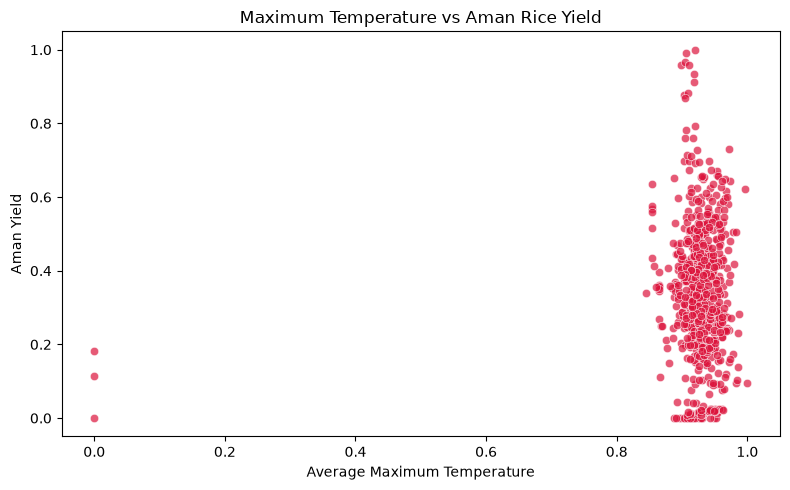

In [17]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Avg_Max_Temp",
    y="Aman_Yield",
    color="crimson",
    alpha=0.7
)

plt.title("Maximum Temperature vs Aman Rice Yield")
plt.xlabel("Average Maximum Temperature")
plt.ylabel("Aman Yield")
plt.tight_layout()
plt.show()

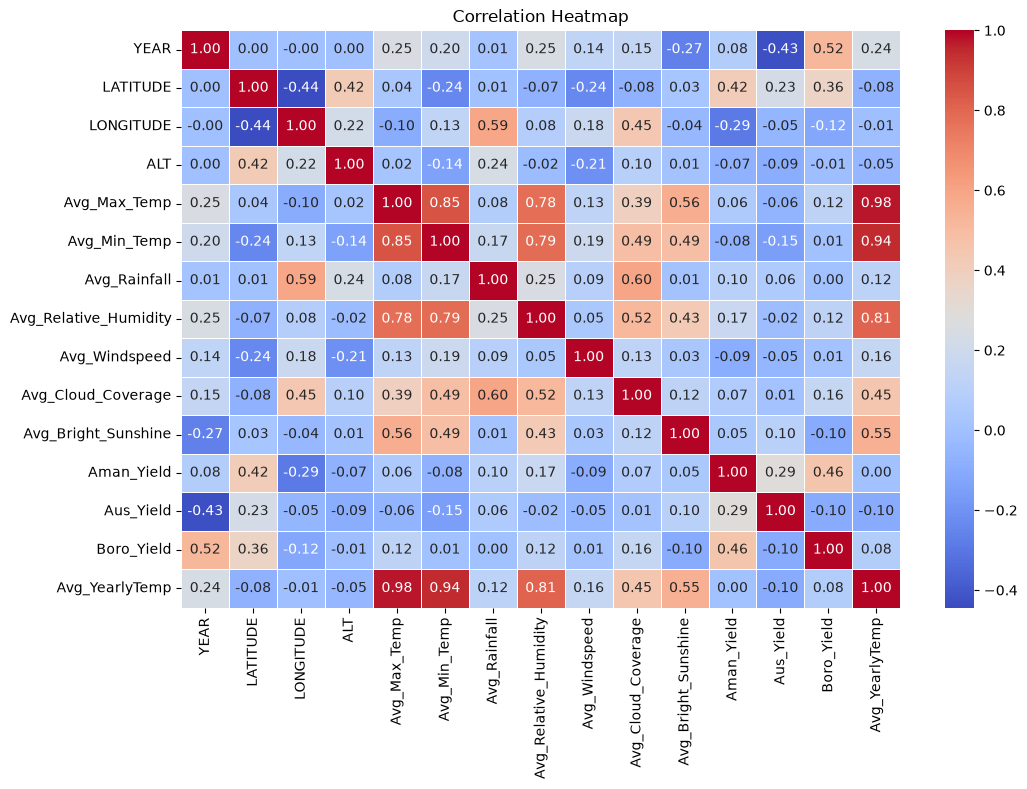

In [18]:
plt.figure(figsize=(11, 8))

corr = df.select_dtypes(include="number").corr()

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [19]:
drop_cols = [
    "Aman_Yield",
    "Aus_Yield",
    "Boro_Yield",
    "Avg_YearlyTemp"
]

X = df.drop(columns=drop_cols)
y = df[target]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (660, 12)
Target: (660,)


In [20]:
X.head()

,YEAR,Station,LATITUDE,LONGITUDE,ALT,Avg_Max_Temp,Avg_Min_Temp,Avg_Rainfall,Avg_Relative_Humidity,Avg_Windspeed,Avg_Cloud_Coverage,Avg_Bright_Sunshine
0,1970,Barisal,0.882582,0.980043,0.063492,0.896552,0.935013,0.436900,0.918843,0.211810,0.805648,0.844641
1,1970,Bogra,0.967341,0.969197,0.317460,0.986437,0.916758,0.324823,0.846082,0.157895,0.684385,0.889872
2,1970,Chittagong (IAP-Patenga),0.868585,0.995553,0.095238,0.893793,0.942680,0.512041,0.901119,0.378691,0.857143,0.822026
3,1970,Comilla,0.912908,0.989046,0.158730,0.921379,0.959109,0.313598,0.953358,0.165597,0.450166,0.776854
4,1970,Dhaka,0.924572,0.980369,0.142857,0.917471,0.940489,0.361217,0.853545,0.225931,0.747508,0.925270


In [21]:
print(X.columns.tolist())

['YEAR', 'Station', 'LATITUDE', 'LONGITUDE', 'ALT', 'Avg_Max_Temp', 'Avg_Min_Temp', 'Avg_Rainfall', 'Avg_Relative_Humidity', 'Avg_Windspeed', 'Avg_Cloud_Coverage', 'Avg_Bright_Sunshine']


In [22]:
print("Minimum year:", X["YEAR"].min())
print("Maximum year:", X["YEAR"].max())

Minimum year: 1970
Maximum year: 2013


In [23]:
from sklearn.model_selection import train_test_split

# Random split of 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (528, 12)
Testing data: (132, 12)


In [24]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorical_features = ["Station"]

preprocessor = ColumnTransformer(
    transformers=[
        ("station", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ],
    remainder="passthrough"
)

In [25]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [28]:
def evaluate_model(model, X_train, y_train, X_test, y_test):
    pipeline = Pipeline([("preprocessor", preprocessor), ("model", model)])
    
    # Simple 5-fold cross-validation 
    cv_scores = cross_validate(pipeline, X_train, y_train, cv=5, 
                               scoring={"r2": "r2", "rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error"})
    
    # Train model & Predict on test data
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    
    # Return metrics directly
    return {
        "Model": model.__class__.__name__,
        "CV R²": cv_scores["test_r2"].mean(),
        "CV RMSE": -cv_scores["test_rmse"].mean(),
        "CV MAE": -cv_scores["test_mae"].mean(),
        "Test R²": r2_score(y_test, y_pred),
        "Test RMSE": mean_squared_error(y_test, y_pred) ** 0.5,  # <-- Yahan parameter hata kar ** 0.5 lagaya hai
        "Test MAE": mean_absolute_error(y_test, y_pred)
    }, pipeline

In [34]:
from sklearn.linear_model import LinearRegression

linear_result, linear_model = evaluate_model(
    LinearRegression(),
    X_train,
    y_train,
    X_test,
    y_test
)

linear_result

{'Model': 'LinearRegression',
 'CV R²': np.float64(0.5831820374679293),
 'CV RMSE': np.float64(0.12226889390498755),
 'CV MAE': np.float64(0.08641387202371975),
 'Test R²': 0.4295198561337553,
 'Test RMSE': 0.1258460688689511,
 'Test MAE': 0.09151765715627672}

In [41]:
from sklearn.ensemble import RandomForestRegressor

rf_result, rf_model = evaluate_model(
    RandomForestRegressor(random_state=42, max_depth=100),
    X_train,
    y_train,
    X_test,
    y_test
)

rf_result

{'Model': 'RandomForestRegressor',
 'CV R²': np.float64(0.7518995928055651),
 'CV RMSE': np.float64(0.09377211496933371),
 'CV MAE': np.float64(0.0580012622964395),
 'Test R²': 0.8004762502489721,
 'Test RMSE': 0.07442463036229682,
 'Test MAE': 0.04877627964492423}

In [42]:
from sklearn.tree import DecisionTreeRegressor

dt_result, dt_model = evaluate_model(
    DecisionTreeRegressor(random_state=42),
    X_train,
    y_train,
    X_test,
    y_test
)

dt_result

{'Model': 'DecisionTreeRegressor',
 'CV R²': np.float64(0.6333976079909959),
 'CV RMSE': np.float64(0.11425051542051357),
 'CV MAE': np.float64(0.06629498432343217),
 'Test R²': 0.41440620526462957,
 'Test RMSE': 0.12750218294465704,
 'Test MAE': 0.06992938792424243}

In [43]:
from sklearn.ensemble import GradientBoostingRegressor

gb_result, gb_model = evaluate_model(
    GradientBoostingRegressor(random_state=42), 
    X_train, 
    y_train, 
    X_test, 
    y_test
)
gb_result

{'Model': 'GradientBoostingRegressor',
 'CV R²': np.float64(0.7332953165454354),
 'CV RMSE': np.float64(0.09719402825128867),
 'CV MAE': np.float64(0.06364544149690217),
 'Test R²': 0.7636142701282116,
 'Test RMSE': 0.08100839264373605,
 'Test MAE': 0.057587150633432053}

In [44]:
from xgboost import XGBRegressor

xgb_result, xgb_model = evaluate_model(
    XGBRegressor(random_state=42), 
    X_train, 
    y_train, 
    X_test, 
    y_test
)
xgb_result

{'Model': 'XGBRegressor',
 'CV R²': np.float64(0.7237027651169348),
 'CV RMSE': np.float64(0.09642486695251314),
 'CV MAE': np.float64(0.05881569057383431),
 'Test R²': 0.7826329232704545,
 'Test RMSE': 0.07768126150509064,
 'Test MAE': 0.051564852129067126}

In [45]:
results_df = pd.DataFrame([
    linear_result,
    dt_result,
    rf_result,
    gb_result,
    xgb_result
])

results_df

,Model,CV R²,CV RMSE,CV MAE,Test R²,Test RMSE,Test MAE
0,LinearRegression,0.583182,0.122269,0.086414,0.429520,0.125846,0.091518
1,DecisionTreeRegressor,0.633398,0.114251,0.066295,0.414406,0.127502,0.069929
2,RandomForestRegressor,0.751900,0.093772,0.058001,0.800476,0.074425,0.048776
3,GradientBoostingRegressor,0.733295,0.097194,0.063645,0.763614,0.081008,0.057587
4,XGBRegressor,0.723703,0.096425,0.058816,0.782633,0.077681,0.051565


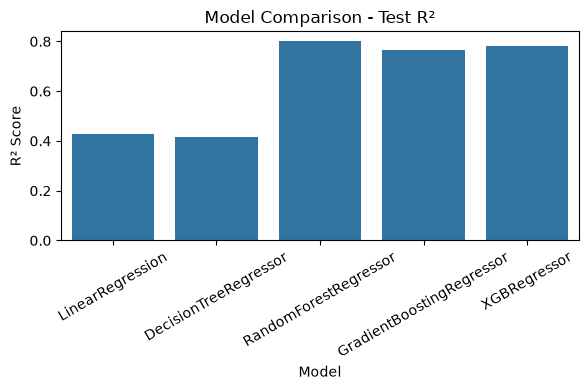

In [49]:
plt.figure(figsize=(6,4))

sns.barplot(
    data=results_df,
    x="Model",
    y="Test R²"
)

plt.title("Model Comparison - Test R²")
plt.xlabel("Model")
plt.ylabel("R² Score")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

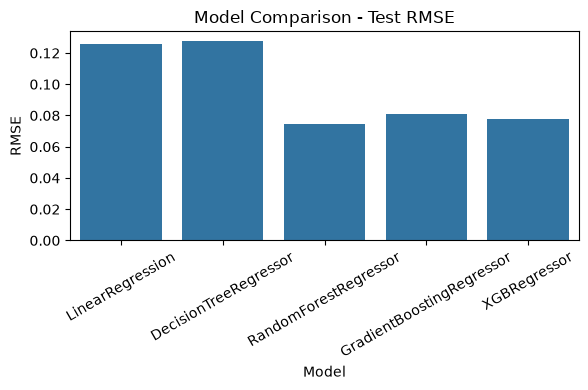

In [50]:
plt.figure(figsize=(6,4))

sns.barplot(
    data=results_df,
    x="Model",
    y="Test RMSE"
)

plt.title("Model Comparison - Test RMSE")
plt.xlabel("Model")
plt.ylabel("RMSE")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [51]:
from sklearn.model_selection import GridSearchCV
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(random_state=42))
])
param_grid = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [None, 10, 20],
    "model__min_samples_split": [2, 5],
    "model__min_samples_leaf": [1, 2]
}
grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)
print("Best Parameters:")
print(grid_search.best_params_)
print("Best CV RMSE:", -grid_search.best_score_)

Best Parameters:
{'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__n_estimators': 300}
Best CV RMSE: 0.09344612284143419


In [52]:
best_rf = grid_search.best_estimator_

y_pred = best_rf.predict(X_test)

test_r2 = r2_score(y_test, y_pred)
test_rmse = mean_squared_error(y_test, y_pred) ** 0.5
test_mae = mean_absolute_error(y_test, y_pred)

print("Tuned Random Forest")
print("Test R²:", test_r2)
print("Test RMSE:", test_rmse)
print("Test MAE:", test_mae)

Tuned Random Forest
Test R²: 0.7969003031722625
Test RMSE: 0.07508860306271525
Test MAE: 0.0487318740829292


In [53]:
best_model = rf_model

y_pred = best_model.predict(X_test)
final_r2 = r2_score(y_test, y_pred)
final_rmse = mean_squared_error(y_test, y_pred) ** 0.5
final_mae = mean_absolute_error(y_test, y_pred)

print("Final Random Forest Performance")
print("R² Score:", round(final_r2, 4))
print("RMSE:", round(final_rmse, 4))
print("MAE:", round(final_mae, 4))

Final Random Forest Performance
R² Score: 0.8005
RMSE: 0.0744
MAE: 0.0488


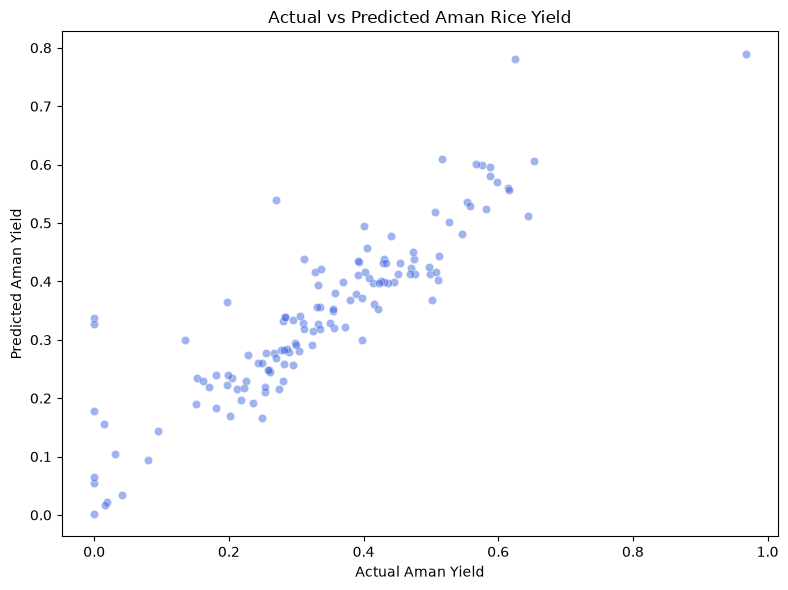

In [55]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=y_test,
    y=y_pred,
    color="royalblue",
    alpha=0.5
)

plt.xlabel("Actual Aman Yield")
plt.ylabel("Predicted Aman Yield")
plt.title("Actual vs Predicted Aman Rice Yield")

plt.tight_layout()
plt.show()

In [56]:
comparison_df = pd.DataFrame({
    "Actual Yield": y_test.values,
    "Predicted Yield": y_pred
})

comparison_df["Error"] = (
    comparison_df["Actual Yield"] -
    comparison_df["Predicted Yield"]
)

comparison_df.head(10)

,Actual Yield,Predicted Yield,Error
0,0.288700,0.279201,0.009499
1,0.304172,0.280326,0.023846
2,0.000000,0.336700,-0.336700
3,0.476169,0.413269,0.062900
4,0.000000,0.177286,-0.177286
5,0.217448,0.196794,0.020654
6,0.197851,0.222080,-0.024229
7,0.297993,0.294992,0.003001
8,0.470105,0.423318,0.046787
9,0.506537,0.518255,-0.011717


In [57]:
comparison_df.round(4)

,Actual Yield,Predicted Yield,Error
0,0.2887,0.2792,0.0095
1,0.3042,0.2803,0.0238
2,0.0000,0.3367,-0.3367
3,0.4762,0.4133,0.0629
4,0.0000,0.1773,-0.1773
...,...,...,...
127,0.2812,0.2829,-0.0017
128,0.5885,0.5810,0.0075
129,0.4536,0.4316,0.0219
130,0.3058,0.3403,-0.0345


In [58]:
import joblib

joblib.dump(best_model, "../models/final_rice_yield_model.pkl")

['../models/final_rice_yield_model.pkl']

## Conclusion

Five regression models were compared for Aman rice yield prediction.
Random Forest achieved the best overall performance among the evaluated models.

Hyperparameter tuning was also performed, but the default Random Forest
performed better than the tuned version. Therefore, the default Random Forest
was selected as the final model.

The final model was evaluated using R², RMSE and MAE and was used to generate
sample rice-yield predictions.